Train: 28417
Test : 8120
Validation: 4060
Class Weights: {0: np.float64(0.865448454393178), 1: np.float64(0.7038440580571655), 2: np.float64(2.3598239495100484)}


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d (Conv1D)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
223/223 ━━━━━━━━━━━━━━━━━━━━ 105s 427ms/step - accuracy: 0.6394 - loss: 0.6582 - val_accuracy: 0.8889 - val_loss: 0.2857 - learning_rate: 0.0010
Epoch 2/20
223/223 ━━━━━━━━━━━━━━━━━━━━ 93s 417ms/step - accuracy: 0.9315 - loss: 0.1718 - val_accuracy: 0.9089 - val_loss: 0.2666 - learning_rate: 0.0010
Epoch 3/20
223/223 ━━━━━━━━━━━━━━━━━━━━ 94s 420ms/step - accuracy: 0.9637 - loss: 0.0907 - val_accuracy: 0.9116 - val_loss: 0.3233 - learning_rate: 0.0010
Epoch 4/20
223/223 ━━━━━━━━━━━━━━━━━━━━ 93s 418ms/step - accuracy: 0.9807 - loss: 0.0505 - val_accuracy: 0.9086 - val_loss: 0.3761 - learning_rate: 0.0010
Epoch 5/20
223/223 ━━━━━━━━━━━━━━━━━━━━ 93s 417ms/step - accuracy: 0.9903 - loss: 0.0278 - val_accuracy: 0.9086 - val_loss: 0.4446 - learning_rate: 5.0000e-04
889/889 ━━━━━━━━━━━━━━━━━━━━ 34s 38ms/step
127/127 ━━━━━━━━━━━━━━━━━━━━ 5s 43ms/step
254/254 ━━━━━━━━━━━━━━━━━━━━ 10s 37ms/step

--- CNN + BiLSTM METRİKLERİ ---
            Accuracy  Precision    Recall  F1-score
Train  

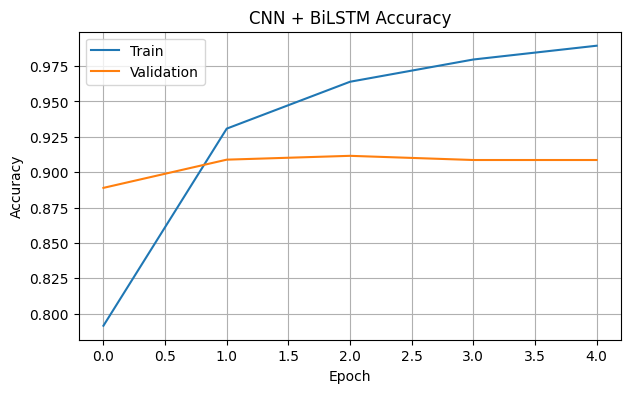

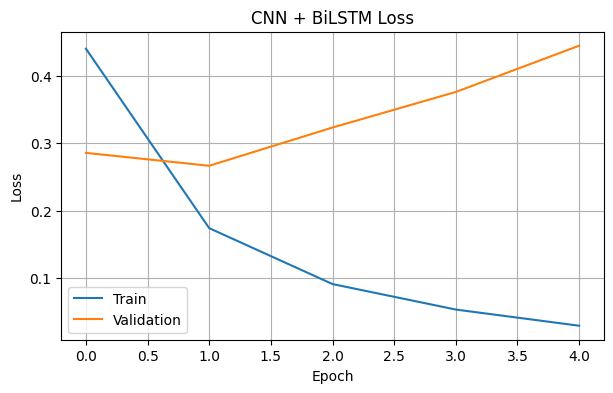

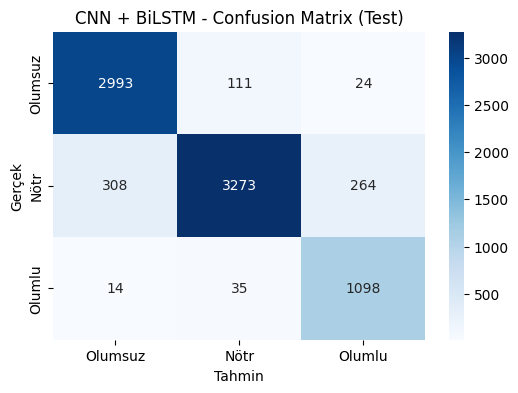

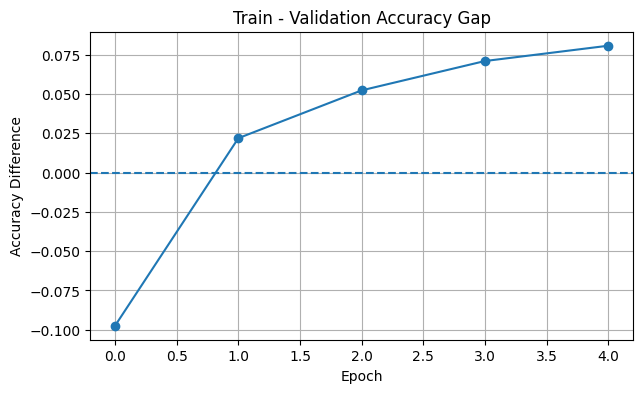

In [1]:
# ===================================================
# 0) KÜTÜPHANELER
# ===================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix
from sklearn.utils.class_weight import compute_class_weight

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, Conv1D, MaxPooling1D, Bidirectional, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.utils import to_categorical


# ===================================================
# 1) VERİ YÜKLEME (SADECE CSV)
# ===================================================

df = pd.read_csv("Turkish-Review-Sentiment-Data.csv")
df.columns = [c.lower() for c in df.columns]

text_col = "review"
label_col = "sentiment"


# ===================================================
# 2) LABEL MAPPING
# ===================================================

label_map = {
    "olumsuz": 0, "negatif": 0,
    "nötr": 1, "notr": 1, "neutral": 1,
    "olumlu": 2, "pozitif": 2, "positive": 2
}

df[label_col] = (
    df[label_col].astype(str).str.lower().map(label_map).fillna(1).astype(int)
)


# ===================================================
# 3) METİN TEMİZLEME
# ===================================================

def clean_text(t):
    if pd.isna(t):
        return ""
    return str(t).lower().replace("\n", " ").strip()

df[text_col] = df[text_col].apply(clean_text)


# ===================================================
# 4) TRAIN / TEST / VALIDATION SPLIT (%70 / %20 / %10)
# ===================================================

X = df[text_col]
y = df[label_col]

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=42
)

X_test, X_val, y_test, y_val = train_test_split(
    X_temp, y_temp, test_size=1/3, stratify=y_temp, random_state=42
)

print("Train:", len(X_train))
print("Test :", len(X_test))
print("Validation:", len(X_val))


# ===================================================
# 5) TOKENIZER + PADDING
# ===================================================

max_words = 30000
max_len = 100

tokenizer = Tokenizer(num_words=max_words, oov_token="<OOV>")
tokenizer.fit_on_texts(X_train)

def tokenize_pad(texts):
    return pad_sequences(
        tokenizer.texts_to_sequences(texts),
        maxlen=max_len,
        padding="post"
    )

X_train_seq = tokenize_pad(X_train)
X_test_seq  = tokenize_pad(X_test)
X_val_seq   = tokenize_pad(X_val)

y_train_cat = to_categorical(y_train, 3)
y_test_cat  = to_categorical(y_test, 3)
y_val_cat   = to_categorical(y_val, 3)


# ===================================================
# 6) CLASS WEIGHT
# ===================================================

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(y_train),
    y=y_train
)

class_weight_dict = dict(enumerate(class_weights))
print("Class Weights:", class_weight_dict)


# ===================================================
# 7) CNN + BiLSTM MODELİ
# ===================================================

model = Sequential([
    Embedding(max_words, 128),

    Conv1D(128, 5, activation="relu"),
    MaxPooling1D(2),

    Bidirectional(LSTM(64, dropout=0.3, recurrent_dropout=0.3)),

    Dense(64, activation="relu"),
    Dropout(0.4),

    Dense(3, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()


# ===================================================
# 8) CALLBACKS
# ===================================================

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    patience=2,
    factor=0.5,
    min_lr=1e-5
)


# ===================================================
# 9) EĞİTİM
# ===================================================

history = model.fit(
    X_train_seq, y_train_cat,
    validation_data=(X_val_seq, y_val_cat),
    epochs=20,
    batch_size=128,
    class_weight=class_weight_dict,
    callbacks=[early_stop, reduce_lr],
    verbose=1
)


# ===================================================
# 10) TAHMİNLER
# ===================================================

train_pred = model.predict(X_train_seq).argmax(axis=1)
val_pred   = model.predict(X_val_seq).argmax(axis=1)
test_pred  = model.predict(X_test_seq).argmax(axis=1)


# ===================================================
# 11) METRİK FONKSİYONU
# ===================================================

def calc_metrics(y_true, y_pred):
    acc = accuracy_score(y_true, y_pred)
    p, r, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average="macro"
    )
    return acc, p, r, f1


# ===================================================
# 12) METRİK TABLOSU
# ===================================================

metrics_df = pd.DataFrame({
    "Accuracy": [
        calc_metrics(y_train, train_pred)[0],
        calc_metrics(y_val, val_pred)[0],
        calc_metrics(y_test, test_pred)[0]
    ],
    "Precision": [
        calc_metrics(y_train, train_pred)[1],
        calc_metrics(y_val, val_pred)[1],
        calc_metrics(y_test, test_pred)[1]
    ],
    "Recall": [
        calc_metrics(y_train, train_pred)[2],
        calc_metrics(y_val, val_pred)[2],
        calc_metrics(y_test, test_pred)[2]
    ],
    "F1-score": [
        calc_metrics(y_train, train_pred)[3],
        calc_metrics(y_val, val_pred)[3],
        calc_metrics(y_test, test_pred)[3]
    ]
}, index=["Train", "Validation", "Test"])

print("\n--- CNN + BiLSTM METRİKLERİ ---")
print(metrics_df)


# ===================================================
# ================== GRAFİKLER ======================
# ===================================================

# 1) Accuracy
plt.figure(figsize=(7,4))
plt.plot(history.history["accuracy"])
plt.plot(history.history["val_accuracy"])
plt.title("CNN + BiLSTM Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend(["Train", "Validation"])
plt.grid(True)
plt.show()

# 2) Loss
plt.figure(figsize=(7,4))
plt.plot(history.history["loss"])
plt.plot(history.history["val_loss"])
plt.title("CNN + BiLSTM Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend(["Train", "Validation"])
plt.grid(True)
plt.show()

# 3) Confusion Matrix – Test
plt.figure(figsize=(6,4))
sns.heatmap(
    confusion_matrix(y_test, test_pred),
    annot=True, fmt="d", cmap="Blues",
    xticklabels=["Olumsuz","Nötr","Olumlu"],
    yticklabels=["Olumsuz","Nötr","Olumlu"]
)
plt.title("CNN + BiLSTM - Confusion Matrix (Test)")
plt.xlabel("Tahmin")
plt.ylabel("Gerçek")
plt.show()

# 4) Train - Validation Accuracy Gap
acc_gap = np.array(history.history["accuracy"]) - np.array(history.history["val_accuracy"])

plt.figure(figsize=(7,4))
plt.plot(acc_gap, marker="o")
plt.axhline(0, linestyle="--")
plt.title("Train - Validation Accuracy Gap")
plt.xlabel("Epoch")
plt.ylabel("Accuracy Difference")
plt.grid(True)
plt.show()
